# AIFit

# Chapter 7

## Action and Active Generalized Filtering

---

This notebook accompanies the implementation of Chapter 7 of

**Fundamentals of Active Inference:
Principles, Algorithms and Applications**

The goal is to translate the concepts of Chapter 7 into executable Python.

Rather than simply reproducing equations, AIFit demonstrates how perception,
action and prediction errors interact during Active Inference.

# Learning Objectives

After completing this notebook you should understand

- the perception–action loop
- hidden states
- observations
- beliefs
- prediction errors
- active control
- free energy
- Bayesian homeostasis

# The Active Inference Cycle

Environment

↓

Observation

↓

Prediction Error

↓

Belief Update

↓

Prediction

↓

Action

↓

Environment

In [ ]:
from aifit.config import SimulationConfig
from aifit.plotting import plot_trajectory
from aifit.simulation import run_simulation

# Simulation Configuration

steps

dt

seed

initial position

preferred temperature

action start

In [3]:
config = SimulationConfig()

config

SimulationConfig(steps=500, dt=0.1, seed=7, action_start_step=100, initial_position=20.0, initial_position_belief=10.0, preferred_temperature=13.0)

# Running the Simulation

The agent starts with an incorrect belief about the hidden state.

Initially only perception is active.

Later action is enabled,
allowing the agent to change the environment.

This reproduces the qualitative behaviour described in Figure 7.6.

Figure saved to: /Users/verenauyka/Projects/AIF/AIFit/notebooks/figures/chapter07/figure_7_6_bayesian_thermostat.png


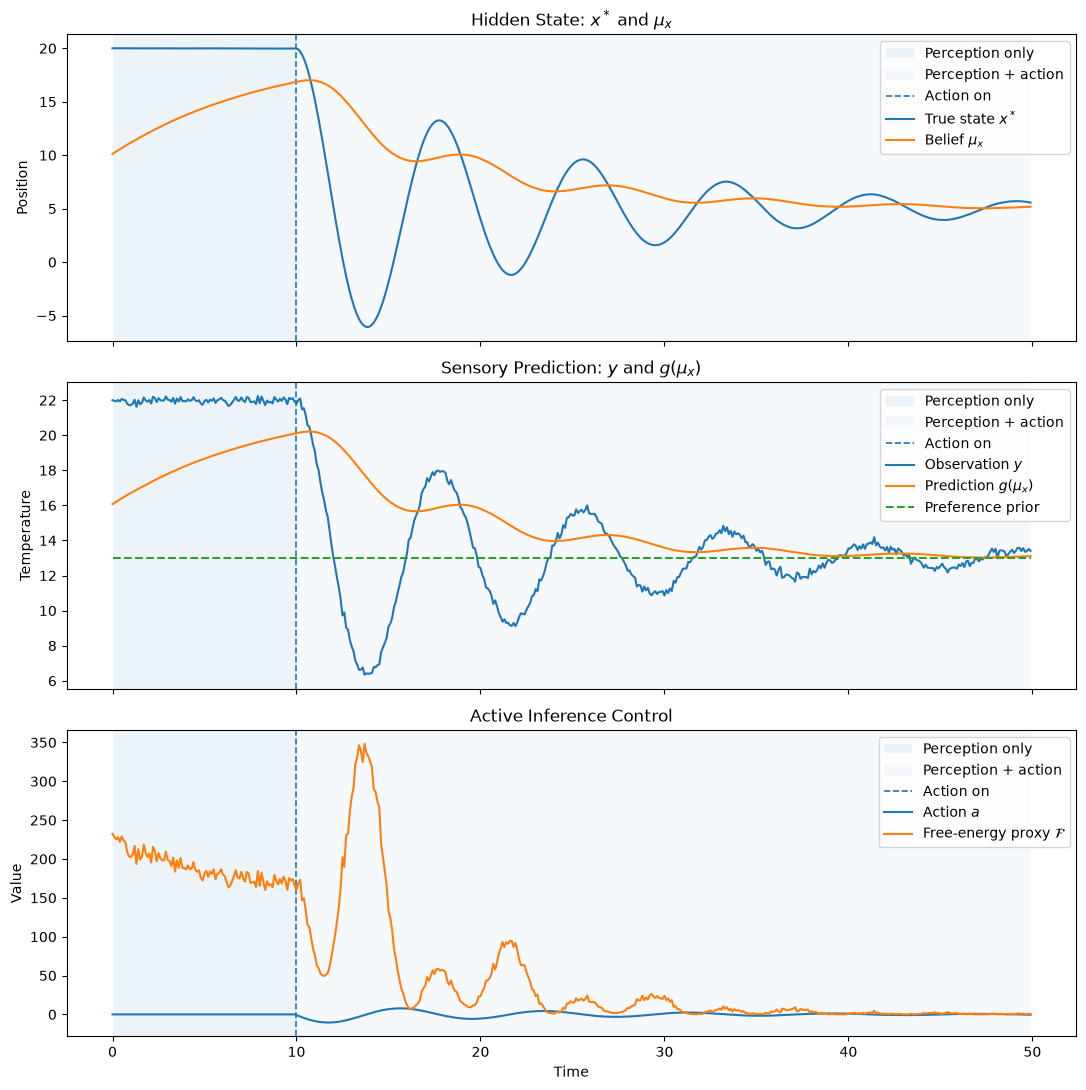

In [4]:
trajectory = run_simulation(config)

plot_trajectory(
    trajectory,
    action_start_time=config.action_start_time,
)

# Interpretation

Initially

prediction

≠

observation

↓

large prediction error

↓

belief updates

↓

prediction improves

↓

action begins

↓

the environment changes

↓

prediction error decreases

↓

free energy decreases

In [5]:
trajectory.keys()

dict_keys(['time', 'true_position', 'belief', 'observation', 'prediction', 'preferred', 'sensory_error', 'preference_error', 'action', 'free_energy'])

In [6]:
trajectory["belief"][:10]

array([10.11520354, 10.22829376, 10.33954073, 10.45096595, 10.55954766,
       10.66969252, 10.77746958, 10.88359577, 10.98472831, 11.08308108])

# Connecting Code to Mathematics

| Mathematics  | Python          |
| ------------ | --------------- |
| (x^*)        | `true_position` |
| (\mu_x)      | `belief`        |
| (y)          | `observation`   |
| (g(\mu_x))   | `prediction`    |
| (a)          | `action`        |
| (\mathcal F) | `free_energy`   |


# Experiments

Try changing

- preferred temperature
- initial belief
- action onset
- noise

How do the trajectories change?

Can you make the agent unstable?

Can you make convergence slower?

Can you make oscillations disappear?

# Discussion

This implementation is intentionally simple.

It captures the qualitative dynamics of Chapter 7 while remaining transparent and easy to understand.

Future chapters will extend this model with

- generalized coordinates
- expected free energy
- policy selection
- learning
- hierarchical generative models

## End of Chapter 7

Next:

**Chapter 8 — Expected Free Energy**

# Exercises

1. Change the preferred temperature from 13°C to 18°C.
2. Double the observation noise.
3. Delay action until t = 20 s.
4. Start with the correct belief. What changes?
5. Increase the action learning rate. Do oscillations become larger?
6. Can you find parameters that make the system unstable?
7. Compare the resulting trajectories with Figure 7.6 in the textbook.